# Tarea 4. Agrupamiento de departamentos según sus patrones temporales
**Entradas:** `dataset2.csv` y `dataset3.csv` (Tarea 2).
Se generan **cuatro agrupamientos**: uno por nivel de formación (técnica profesional, tecnológica, universitaria) y uno para la variación del porcentaje oficial.

## Selección del algoritmo (justificación)
- **Vector de características:** las 9 tasas (o variaciones) de cada departamento, es decir, cada departamento es un punto en $\mathbb{R}^9$ y sus coordenadas son la señal temporal.
- **Medida de similitud:** distancia euclídea. Todas las coordenadas tienen la misma unidad (%, o pp) y el orden temporal es el mismo para todos los departamentos, por lo que no se escala por columna y se compara la forma y el nivel de la señal.
- **Algoritmo candidato principal: K-means.** Con solo 33 puntos y grupos esperados de forma compacta, es simple e interpretable (centroide = perfil temporal típico del grupo). Se compara con *clustering jerárquico (Ward)* y *GMM (covarianza diagonal)* usando el coeficiente de silueta.
- **DBSCAN se descarta:** con 33 puntos en 9 dimensiones no hay densidad suficiente para fijar `eps`/`min_samples` de forma estable, y tendería a marcar como ruido a los departamentos pequeños con crecimientos extremos, que justamente interesa agrupar.
- **Valores extremos:** hay departamentos con bases muy pequeñas cuyas tasas llegan a cientos o miles de % (p. ej. Cauca en técnica profesional). Sin tratamiento, K-means (y los otros métodos) dedica un grupo entero a cada uno de esos casos. Por eso, antes de agrupar, cada columna se **recorta (winsoriza) entre los percentiles 5 y 95**: los extremos siguen siendo los más altos/bajos de su columna, pero ya no dominan la distancia.
- **Número de grupos:** no es obligatorio; se elige $k\in[2,6]$ con el mayor coeficiente de silueta, **exigiendo que todos los grupos tengan al menos 3 departamentos** (`MIN_TAM`).

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

os.makedirs("figuras", exist_ok=True)
SEED = 42
ALGORITMO = "K-means"       # "K-means", "Jerárquico (Ward)" o "GMM"
K_FIJO = None               # poner un entero para forzar k; None = elegir por silueta
WINSOR = (0.05, 0.95)       # recorte por columna antes de agrupar
MIN_TAM = 3                 # tamaño mínimo aceptado por grupo al elegir k

ds2 = pd.read_csv("dataset2.csv")
ds3 = pd.read_csv("dataset3.csv")
COLS = [c for c in ds2.columns if c not in ("departamento", "nivel")]

DATOS = {
    "Técnica profesional": ds2[ds2["nivel"] == "tecnica"].set_index("departamento")[COLS],
    "Tecnológica": ds2[ds2["nivel"] == "tecnologica"].set_index("departamento")[COLS],
    "Universitaria": ds2[ds2["nivel"] == "universitaria"].set_index("departamento")[COLS],
    "Porcentaje oficial": ds3.set_index("departamento")[COLS],
}
def winsorizar(X, lim=WINSOR):
    """Recorta cada columna entre sus percentiles lim[0] y lim[1] para que los extremos no dominen la distancia."""
    return X.clip(X.quantile(lim[0]), X.quantile(lim[1]), axis=1)

DATOS = {k: winsorizar(v) for k, v in DATOS.items()}      # a partir de aquí el algoritmo ve los datos recortados
for k, v in DATOS.items():
    print(f"{k}: {v.shape[0]} departamentos")

Técnica profesional: 27 departamentos
Tecnológica: 33 departamentos
Universitaria: 33 departamentos
Porcentaje oficial: 33 departamentos


In [3]:
def modelo(nombre, k):
    if nombre == "K-means":
        return KMeans(n_clusters=k, n_init=10, random_state=SEED)
    if nombre == "Jerárquico (Ward)":
        return AgglomerativeClustering(n_clusters=k, linkage="ward")
    if nombre == "GMM":
        return GaussianMixture(n_components=k, covariance_type="diag", random_state=SEED)
    raise ValueError(nombre)

ALGORITMOS = ["K-means", "Jerárquico (Ward)", "GMM"]

def silueta(X, k, algoritmo):
    """Silueta del agrupamiento; NaN si algún grupo tiene menos de MIN_TAM departamentos o no es calculable."""
    if k >= len(X):
        return np.nan
    lab = modelo(algoritmo, k).fit_predict(X)
    if len(set(lab)) < 2 or np.bincount(lab).min() < MIN_TAM:
        return np.nan
    return silhouette_score(X, lab)

def comparar(X, ks=range(2, 7)):
    return pd.DataFrame({a: [silueta(X, k, a) for k in ks] for a in ALGORITMOS}, index=list(ks)).rename_axis("k")

def agrupar(X, algoritmo=ALGORITMO, k_fijo=K_FIJO):
    """Devuelve (etiquetas 1..k ordenadas de mayor a menor media, k, tabla de silueta)."""
    tabla = comparar(X)
    if k_fijo is None:
        k = int(tabla[algoritmo].idxmax()) if tabla[algoritmo].notna().any() else 2
    else:
        k = k_fijo
    lab = modelo(algoritmo, k).fit_predict(X)
    orden = X.groupby(lab).mean().mean(axis=1).sort_values(ascending=False).index   # Grupo 1 = mayor valor medio
    mapa = {viejo: i + 1 for i, viejo in enumerate(orden)}
    return pd.Series([mapa[l] for l in lab], index=X.index, name="grupo"), k, tabla

def graficar(X, grupos, titulo, archivo):
    """Izquierda: proyección PCA 2D. Derecha: perfil temporal de cada grupo."""
    G = sorted(grupos.unique())
    colores = plt.cm.tab10(np.arange(len(G)))
    pca = PCA(n_components=2, random_state=SEED)
    Z = pca.fit_transform(X.values)
    fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
    for g, c in zip(G, colores):
        idx = (grupos == g).values
        ax[0].scatter(Z[idx, 0], Z[idx, 1], color=c, s=60, label=f"Grupo {g} (n={idx.sum()})")
        for (x, y), nom in zip(Z[idx], X.index[idx]):
            ax[0].annotate(nom, (x, y), fontsize=7, xytext=(3, 3), textcoords="offset points")
        for dep in X.index[idx]:
            ax[1].plot(range(1, len(COLS) + 1), X.loc[dep].values, color=c, alpha=0.18)
        ax[1].plot(range(1, len(COLS) + 1), X[idx].mean().values, color=c, lw=3, label=f"Grupo {g}")
    ax[0].set_title(f"{titulo}\nProyección PCA ({pca.explained_variance_ratio_.sum():.0%} de la varianza)")
    ax[0].set_xlabel("Componente 1"); ax[0].set_ylabel("Componente 2"); ax[0].legend(); ax[0].grid(alpha=0.3)
    ax[1].set_title("Perfil medio por grupo (gruesa) y departamentos (finas)\n[valores recortados p5–p95]")
    ax[1].set_xlabel("n (intervalo 2016–2017 a 2024–2025)"); ax[1].set_ylabel("Tasa (%) / variación (pp)")
    ax[1].set_xticks(range(1, len(COLS) + 1)); ax[1].axhline(0, color="k", lw=0.8); ax[1].legend(); ax[1].grid(alpha=0.3)
    plt.tight_layout(); fig.savefig(f"figuras/{archivo}", dpi=150); plt.show()

def miembros(grupos):
    for g in sorted(grupos.unique()):
        print(f"Grupo {g}: " + ", ".join(sorted(grupos[grupos == g].index)))

RESULTADOS = {}
def correr(nombre, archivo):
    X = DATOS[nombre]
    grupos, k, tabla = agrupar(X)
    RESULTADOS[nombre] = grupos
    print(f"== {nombre} | algoritmo: {ALGORITMO} | k = {k} ==")
    print(f"Silueta por algoritmo y k (NaN = algún grupo con menos de {MIN_TAM} departamentos):")
    display(tabla.round(3))
    graficar(X, grupos, nombre, archivo)
    miembros(grupos)

## (a) Técnica profesional

== Técnica profesional | algoritmo: K-means | k = 3 ==
Silueta por algoritmo y k (NaN = algún grupo con menos de 3 departamentos):


,K-means,Jerárquico (Ward),GMM
k,,,
2,0.318,0.255,NaN
3,0.375,0.322,NaN
4,NaN,NaN,NaN
5,NaN,NaN,NaN
6,NaN,NaN,NaN


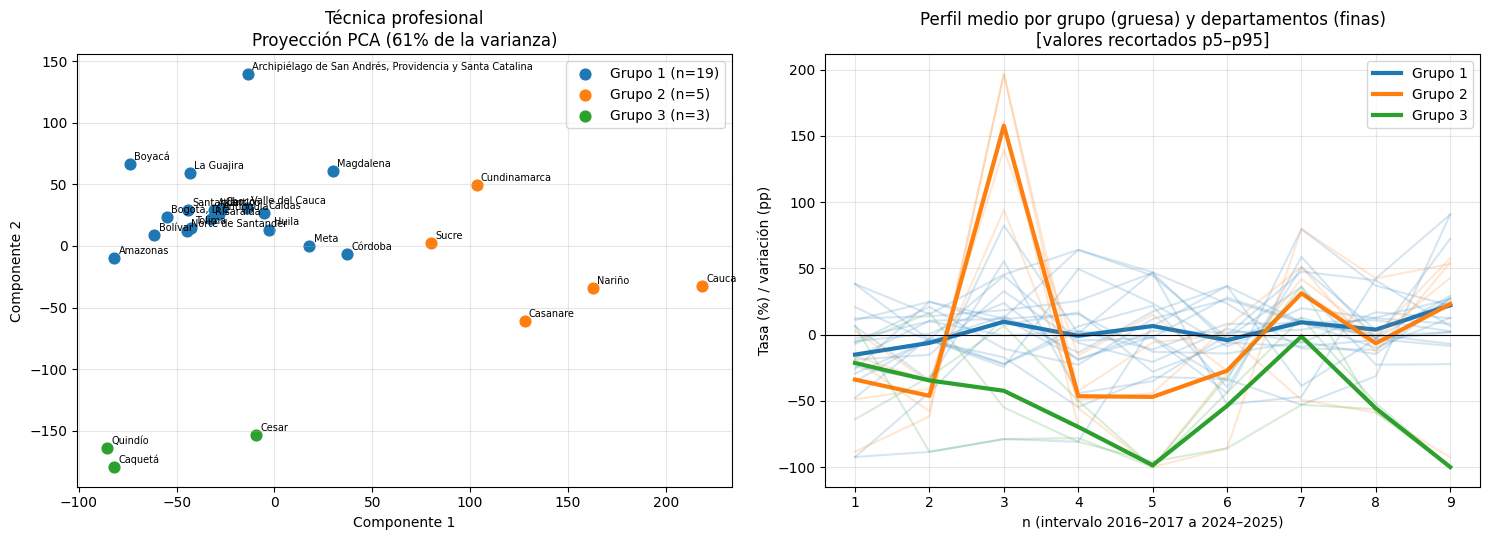

Grupo 1: Amazonas, Antioquia, Archipiélago de San Andrés, Providencia y Santa Catalina, Atlántico, Bogotá, D.C., Bolívar, Boyacá, Caldas, Chocó, Córdoba, Huila, La Guajira, Magdalena, Meta, Norte de Santander, Risaralda, Santander, Tolima, Valle del Cauca
Grupo 2: Casanare, Cauca, Cundinamarca, Nariño, Sucre
Grupo 3: Caquetá, Cesar, Quindío


In [4]:
correr("Técnica profesional", "t4_tecnica.png")

## (b) Tecnológica

== Tecnológica | algoritmo: K-means | k = 2 ==
Silueta por algoritmo y k (NaN = algún grupo con menos de 3 departamentos):


,K-means,Jerárquico (Ward),GMM
k,,,
2,0.170,NaN,0.304
3,NaN,NaN,NaN
4,0.161,NaN,NaN
5,NaN,NaN,NaN
6,NaN,NaN,NaN


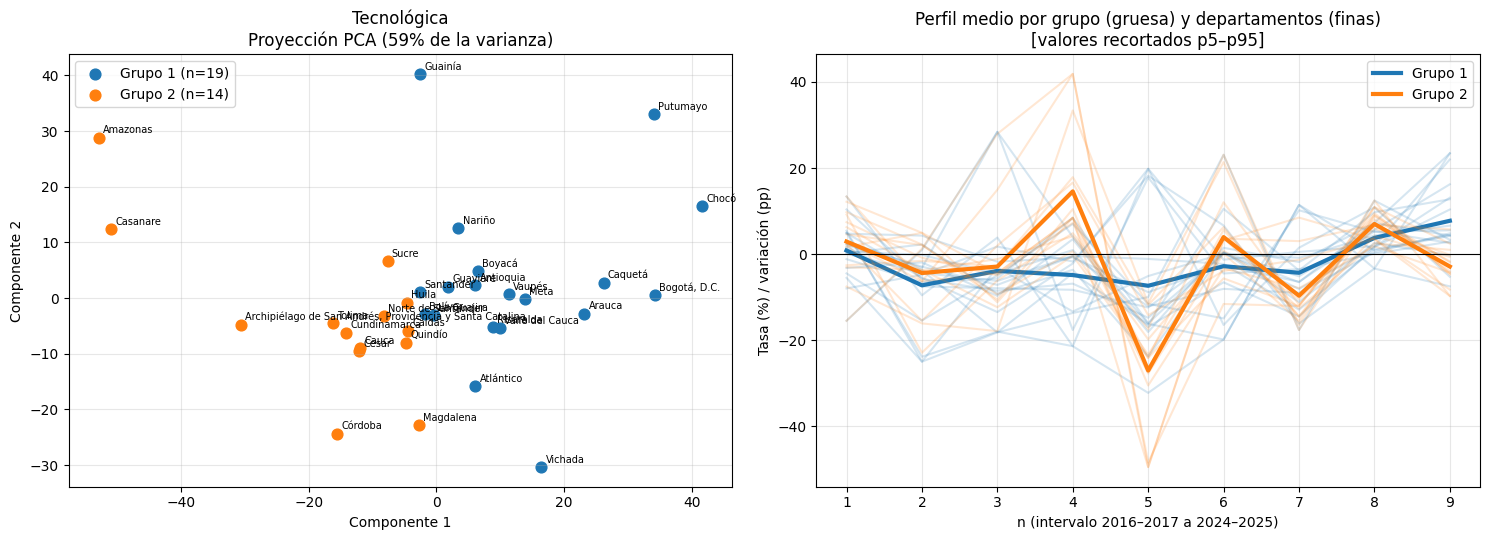

Grupo 1: Antioquia, Arauca, Atlántico, Bogotá, D.C., Bolívar, Boyacá, Caquetá, Chocó, Guainía, Guaviare, La Guajira, Meta, Nariño, Putumayo, Risaralda, Santander, Valle del Cauca, Vaupés, Vichada
Grupo 2: Amazonas, Archipiélago de San Andrés, Providencia y Santa Catalina, Caldas, Casanare, Cauca, Cesar, Cundinamarca, Córdoba, Huila, Magdalena, Norte de Santander, Quindío, Sucre, Tolima


In [5]:
correr("Tecnológica", "t4_tecnologica.png")

## (c) Universitaria

== Universitaria | algoritmo: K-means | k = 2 ==
Silueta por algoritmo y k (NaN = algún grupo con menos de 3 departamentos):


,K-means,Jerárquico (Ward),GMM
k,,,
2,0.618,0.637,0.637
3,0.563,NaN,0.457
4,NaN,NaN,NaN
5,NaN,NaN,NaN
6,NaN,NaN,NaN


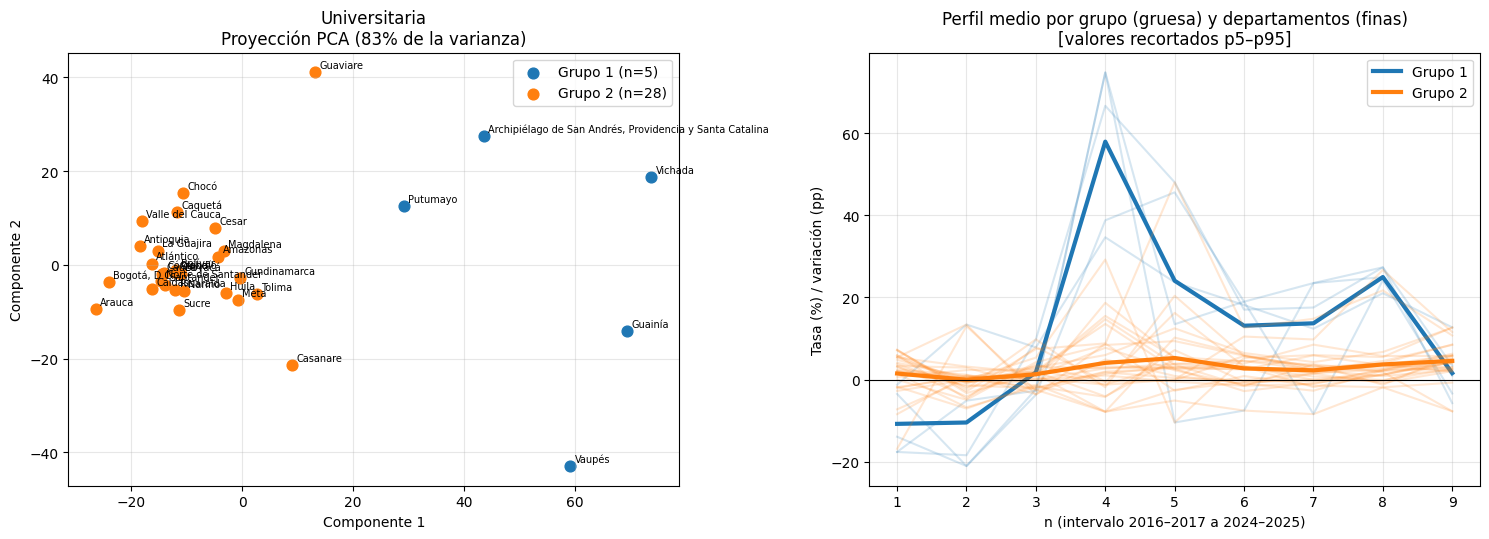

Grupo 1: Archipiélago de San Andrés, Providencia y Santa Catalina, Guainía, Putumayo, Vaupés, Vichada
Grupo 2: Amazonas, Antioquia, Arauca, Atlántico, Bogotá, D.C., Bolívar, Boyacá, Caldas, Caquetá, Casanare, Cauca, Cesar, Chocó, Cundinamarca, Córdoba, Guaviare, Huila, La Guajira, Magdalena, Meta, Nariño, Norte de Santander, Quindío, Risaralda, Santander, Sucre, Tolima, Valle del Cauca


In [6]:
correr("Universitaria", "t4_universitaria.png")

## (d) Variación del porcentaje oficial

== Porcentaje oficial | algoritmo: K-means | k = 2 ==
Silueta por algoritmo y k (NaN = algún grupo con menos de 3 departamentos):


,K-means,Jerárquico (Ward),GMM
k,,,
2,0.483,0.483,0.372
3,0.181,0.153,NaN
4,NaN,NaN,NaN
5,NaN,NaN,NaN
6,NaN,NaN,NaN


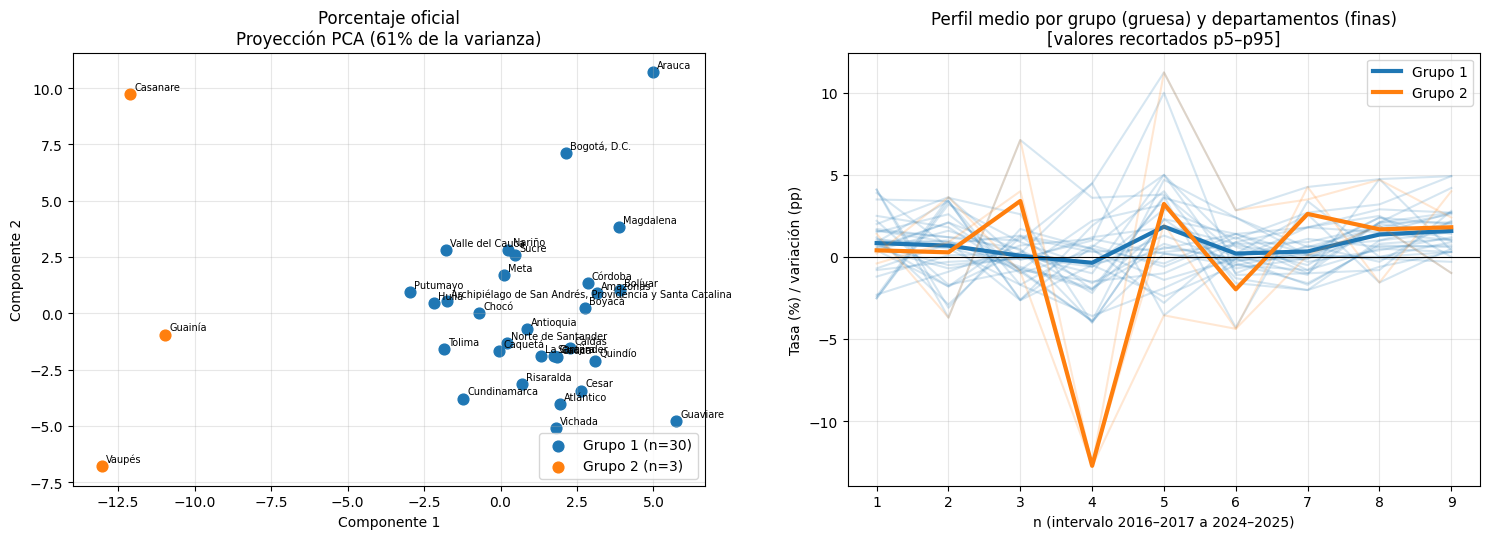

Grupo 1: Amazonas, Antioquia, Arauca, Archipiélago de San Andrés, Providencia y Santa Catalina, Atlántico, Bogotá, D.C., Bolívar, Boyacá, Caldas, Caquetá, Cauca, Cesar, Chocó, Cundinamarca, Córdoba, Guaviare, Huila, La Guajira, Magdalena, Meta, Nariño, Norte de Santander, Putumayo, Quindío, Risaralda, Santander, Sucre, Tolima, Valle del Cauca, Vichada
Grupo 2: Casanare, Guainía, Vaupés


In [7]:
correr("Porcentaje oficial", "t4_oficial.png")

## Tabla de asignación de departamentos a grupos

In [8]:
asignacion = pd.DataFrame(RESULTADOS).rename(columns={
    "Técnica profesional": "grupo_tecnica", "Tecnológica": "grupo_tecnologica",
    "Universitaria": "grupo_universitaria", "Porcentaje oficial": "grupo_oficial"})
asignacion = asignacion.rename_axis("departamento").reset_index()
asignacion.to_csv("asignacion_grupos.csv", index=False)
print("Guardado asignacion_grupos.csv:", asignacion.shape, "(NaN = departamento excluido de ese agrupamiento en la Tarea 2)")
pd.read_csv("asignacion_grupos.csv")

Guardado asignacion_grupos.csv: (33, 5) (NaN = departamento excluido de ese agrupamiento en la Tarea 2)


,departamento,grupo_tecnica,grupo_tecnologica,grupo_universitaria,grupo_oficial
0,Amazonas,1.0,2,2,1
1,Antioquia,1.0,1,2,1
2,Arauca,NaN,1,2,1
3,"Archipiélago de San Andrés, Providencia y Sant...",1.0,2,1,1
4,Atlántico,1.0,1,2,1
5,"Bogotá, D.C.",1.0,1,2,1
6,Bolívar,1.0,1,2,1
7,Boyacá,1.0,1,2,1
8,Caldas,1.0,2,2,1
9,Caquetá,3.0,1,2,1


## Contexto socioeconómico verificado (para las preguntas de análisis)
Cifras del DANE (cuentas departamentales) citadas por la prensa económica; el PIB per cápita corresponde a 2023 y la participación en el PIB a 2024 preliminar.
- **Concentración económica:** Bogotá aportó 25,2 % del PIB nacional en 2024, Antioquia 14,8 %, Valle del Cauca 9,7 % y Santander 6,4 %.
- **PIB per cápita 2023 (promedio nacional: $30,3 millones):** Bogotá $50,0 M; Casanare $49,3 M; Meta $47,6 M; Santander $43,0 M; San Andrés $36,7 M; Antioquia $33,7 M; Valle del Cauca $33,1 M; Boyacá $32,6 M.
- **Casanare y Meta:** su alto PIB per cápita se debe al petróleo (cerca de la mitad de su PIB), según el DANE.
- **Periferia:** Vichada, Vaupés, Guainía y Chocó tienen un PIB per cápita cercano a un tercio del promedio nacional; Guainía y Vaupés son los departamentos con menor PIB. En el Caribe el PIB per cápita ronda $20 M frente a $32 M a nivel nacional.

Fuentes: Valora Analitik (28-mar-2025) con datos del DANE; boletín técnico DANE PIB departamental 2024; BBVA Research, *El mapa económico de Colombia*; La República (Costa Caribe). Para la tabla completa de los 33 departamentos, descargar el anexo "PIB total por departamentos" en
https://www.dane.gov.co/index.php/estadisticas-por-tema/cuentas-nacionales/cuentas-nacionales-departamentales

## Preguntas de análisis
Responder con apoyo en información verificable (ubicación geográfica, PIB departamental, presencia de IES grandes, oferta del SENA, etc.). Las explicaciones socioeconómicas no deben presentarse como relaciones causales.

**Nivel de formación**
1. ¿Qué características comparten los departamentos de un mismo grupo (ubicación, nivel de riqueza, desarrollo económico, otras variables)?
   *Respuesta:* …
2. ¿Algún departamento resulta inesperado en su grupo? ¿Qué explicaciones posibles hay?
   *Respuesta:* …

**Porcentaje oficial**
3. ¿Qué características geográficas, económicas y socioeconómicas comparten los departamentos de un mismo grupo?
   *Respuesta:* …
4. ¿Algún departamento resulta inesperado? ¿Qué factores podrían explicarlo?
   *Respuesta:* …

*Ayuda:* departamentos pequeños (Amazonía, Orinoquía) con matrícula de pocos cientos de estudiantes producen tasas muy volátiles, y el peso del SENA (sector oficial) puede explicar cambios bruscos del porcentaje oficial.